This notebook follows the [01 data preparation notebook](https://github.com/ycma-data/DSC-680-Capstone/blob/main/notebooks/01_data_preparation.ipynb) and the [02 EDA notebook](https://github.com/ycma-data/DSC-680-Capstone/blob/main/notebooks/02_EDA.ipynb).

## Step 0. Notebook setup

In [ ]:
## Notebook setup & library loading

import os
import pandas as pd
pd.set_option('display.float_format', '{:,.3f}'.format)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', None)

from matplotlib import pyplot as plt
%matplotlib inline

import numpy as np
np.set_printoptions(suppress=True)

# scikit-learn: preprocessing, models, cross-validation, tuning, and metrics
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV
from sklearn.metrics import (f1_score, precision_score, recall_score, confusion_matrix, matthews_corrcoef,
                             balanced_accuracy_score, roc_auc_score, average_precision_score)
SEED = 42
np.random.seed(SEED)

In [ ]:
# Packages & Libraries needed to load data from Google Drive, and imbalanced-learn for SMOTE
# https://pypi.org/project/PyDrive2/

!pip install -U -q PyDrive2
!pip install -q imbalanced-learn
!pip install -q shap
from pydrive2.auth import GoogleAuth
from pydrive2.drive import GoogleDrive
from google.colab import auth
from oauth2client.client import GoogleCredentials
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Package versions reported in the paper
import imblearn, matplotlib, shap
print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__)
print('imbalanced-learn', imblearn.__version__, '| shap', shap.__version__, '| matplotlib', matplotlib.__version__)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
joserfc 1.8.0 requires cryptography>=45.0.1, but you have cryptography 43.0.3 which is incompatible.
authlib 1.9.3 requires cryptography>=45.0.1, but you have cryptography 43.0.3 which is incompatible.
pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1
imbalanced-learn 0.14.2 | shap 0.54.1 | matplotlib 3.10.0


In [ ]:
# Data loading: the analysis file made by notebook 01, stored in the GitHub repository
url = 'https://raw.githubusercontent.com/ycma-data/DSC-680-Capstone/main/data/institutions.csv'
df = pd.read_csv(url)
print("institutions.csv Data Shape: ", df.shape)

institutions.csv Data Shape:  (1608, 54)


In [ ]:
# Folders for outcomes
FIG_DIR = '/content/figures'
RESULTS_DIR = '/content/results'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=200, bbox_inches='tight')

def save_table(table, name):
    table.to_csv(f'{RESULTS_DIR}/{name}.csv')

# Run settings
N_FOLDS = 5          # stratified 5-fold cross-validation (outer folds)
N_REPEATS = 10       # repeated 10 times: 50 test folds per model (set to 2 for a quick test run)
TUNE = True          # small tuning grid inside each training fold (set to False for a quick test run)
DROP_REPEATS = 2     # repeats for the "remove one group" check in Step 4 (10 test folds; it refits many models)
N_TREES = 300        # trees in each random forest

# The small tuning grids (Week 2 plan). Each grid is searched with stratified 3-fold cross-validation
# inside the training fold only, so the test fold never informs the choice
GRIDS = {'baseline': {'model__C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]},              # strength of the penalty in logistic regression
         'logistic': {'model__C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]},
         'forest': {'model__min_samples_leaf': [1, 5, 10, 20, 50, 100]}}         # smallest number of colleges in a leaf

In [ ]:
# larger fonts
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 13, 'axes.labelsize': 12,
                     'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11})

def tidy(table, digits=3):
    # round, and show tiny negative values (such as -0.0004) as 0.000 instead of -0.000
    return table.round(digits) + 0.0

## Step 1. Preparation for modeling

This step prepares the inputs before any model is fit.

**1.1 Define the groups of characteristics**

Define the characterisitcs in each group, which ones are categoris, and which ones get the log in logistic regression, and set the readable names and colors for the tables and figures. For the sector models (Sub-Q2), the groups leave out sector, because sector does not vary inside a sector.

In [ ]:
# groups of characteristics
GROUPS = {
    'sector': ['CONTROL'],
    'location': ['REGION', 'LOCALE'],
    'size': ['log_enroll', 'C18BASIC', 'multi_campus'],
    'selectivity': ['ADM_RATE', 'OPENADMP', 'no_first_time'],
    'price': ['TUITIONFEE_IN', 'net_price', 'grant_aid_intensity'],
    'finances': ['TUITFTE', 'INEXPFTE', 'endow_per_student', 'AVGFACSAL'],
    'student body': ['PCTPELL', 'PCTFLOAN', 'UGDS_BLACK', 'UGDS_HISP', 'UGDS_ASIAN', 'UGDS_NRA', 'PPTUG_EF', 'HBCU'],
    'student outcomes': ['C150_4', 'RET_FT4', 'CDR3', 'MD_EARN_WNE_P7', 'DEBT_MDN'],
    'pre-2018 trend': ['trend_13_18'],
}
CATEGORICAL = ['CONTROL', 'REGION', 'LOCALE', 'C18BASIC', 'OPENADMP', 'HBCU']   # coded categories: one-hot encoded
LOG_COLS = ['endow_per_student', 'INEXPFTE']        # log for logistic regression only (EDA, Step 9)

ALL_FEATURES = []
group_of = {}
for g, cols in GROUPS.items():
    ALL_FEATURES += cols
    for c in cols:
        group_of[c] = g

In [ ]:
# groups for the sector models (without sector)
SECTOR_GROUPS = {}
for g, cols in GROUPS.items():
    if g != 'sector':
        SECTOR_GROUPS[g] = cols
SECTOR_FEATURES = [c for c in ALL_FEATURES if c != 'CONTROL']

# readable names and colors
nice_names = {
    'log_enroll': 'log of enrollment', 'multi_campus': 'more than one campus', 'ADM_RATE': 'admission rate',
    'no_first_time': 'no first-time students', 'TUITIONFEE_IN': 'in-state tuition and fees ($)', 'net_price': 'net price ($)',
    'grant_aid_intensity': 'grant aid intensity', 'TUITFTE': 'net tuition revenue per student ($)',
    'INEXPFTE': 'instructional spending per student ($)', 'endow_per_student': 'endowment per student ($)',
    'AVGFACSAL': 'average faculty salary ($ per month)', 'PCTPELL': 'share with Pell grants',
    'PCTFLOAN': 'share with federal loans', 'UGDS_BLACK': 'share of Black students', 'UGDS_HISP': 'share of Hispanic students',
    'UGDS_ASIAN': 'share of Asian students', 'UGDS_NRA': 'share of nonresident students', 'PPTUG_EF': 'share of part-time students',
    'C150_4': 'completion rate', 'RET_FT4': 'retention rate', 'CDR3': 'default rate (3-year)',
    'MD_EARN_WNE_P7': 'median earnings after 7 years ($)', 'DEBT_MDN': 'median debt ($)', 'trend_13_18': 'pre-2018 trend (log change)',
}
group_colors = {'sector': '#7F7F7F', 'location': '#8172B3', 'size': '#4C72B0', 'selectivity': '#DD8452', 'price': '#55A868',
                'finances': '#C44E52', 'student body': '#937860', 'student outcomes': '#DA8BC3', 'pre-2018 trend': '#64B5CD'}
label_order = ['resilient', 'recovered', 'vulnerable']

**1.2 Check for values that cannot be real**

Check every numeric characteristic for zeros, negative values, and shares or rates above 1. A zero is impossible for some characteristics such as instructional spending, but normal for others such as the share of students with federal loans. The pre-2018 trend and the two y/n flags are left out, because 0 or a negative value is normal.

In [ ]:
check_feats = [c for c in ALL_FEATURES if c not in CATEGORICAL and c not in ['trend_13_18', 'multi_campus', 'no_first_time']]
shares = ['ADM_RATE', 'grant_aid_intensity', 'PCTPELL', 'PCTFLOAN', 'UGDS_BLACK', 'UGDS_HISP', 'UGDS_ASIAN',
          'UGDS_NRA', 'PPTUG_EF', 'C150_4', 'RET_FT4', 'CDR3']
check = pd.DataFrame({'zeros': (df[check_feats] == 0).sum(),
                      'negative': (df[check_feats] < 0).sum(),
                      'above 1 (shares and rates only)': (df[shares] > 1).sum().reindex(check_feats).astype('Int64'),
                      'minimum': df[check_feats].min()}).loc[check_feats]
print(check.rename(index=nice_names).to_string())

                                        zeros  negative  above 1 (shares and rates only)    minimum
log of enrollment                           0         0                             <NA>      4.625
admission rate                              1         0                                0      0.000
in-state tuition and fees ($)               0         0                             <NA>  2,684.000
net price ($)                               0         1                             <NA> -1,133.000
grant aid intensity                         0         0                                1      0.036
net tuition revenue per student ($)         0         0                             <NA>      4.000
instructional spending per student ($)      1         0                             <NA>      0.000
endowment per student ($)                   0         0                             <NA>      0.299
average faculty salary ($ per month)        0         0                             <NA>  1,236.000


List the colleges behind the unusual values: zeros where 0 cannot be real (every college spends on instruction and pays its faculty, and an admitting college cannot have an admission rate of 0), the negative net price, grant aid above the cost of attendance, and completion rates of 0.

In [ ]:
# zeros that cannot be real
print()
for col in ['INEXPFTE', 'AVGFACSAL', 'ADM_RATE']:
    names = df.loc[df[col] == 0, 'INSTNM'].tolist()
    print(nice_names[col], '= 0 for:', names if names else '(none)')

# other unusual values
print()
print('Negative net price:', df.loc[df['net_price'] < 0, 'INSTNM'].tolist())
print('Grant aid intensity above 1:', df.loc[df['grant_aid_intensity'] > 1, 'INSTNM'].tolist())
print()
print('Completion rate = 0:')
print(df.loc[df['C150_4'] == 0, ['INSTNM', 'T2018', 'PPTUG_EF']].astype({'T2018': int}).to_string(index=False))


instructional spending per student ($) = 0 for: ['Thomas Edison State University']
average faculty salary ($ per month) = 0 for: (none)
admission rate = 0 for: ['Saint Anthony College of Nursing']

Negative net price: ['Oglala Lakota College']
Grant aid intensity above 1: ['Oglala Lakota College']

Completion rate = 0:
                                              INSTNM  T2018  PPTUG_EF
                                 Bellevue University   6377     0.341
                              Nazarene Bible College    555     0.876
                          City University of Seattle    651     0.747
       Polytechnic University of Puerto Rico-Orlando   3709     0.667
                      Luther Rice College & Seminary    293     0.826
South Florida Bible College and Theological Seminary    171     0.672
                  University of Massachusetts Global   4062     0.701
                       University of Saint Katherine    196     0.128


The check found two impossible zeros:
*    0 instructional spending at Thomas Edison State University
*    0 admission rate at Saint Anthony College of Nursing
These zeros are most likely not real measurements. Thomas Edison had about 10,000 studnets in 2018, so its instructional spending could not have been zero. Because it mainly serves online students, so it may report its costs differently. Saint Anothony admits nursing students as juniors only, and has no freshman applicants, so an admission rate does not apply to it.
Since the other characteristecs of these two colleges are valid, both stay in the sample and the zero values are set to missing.

Oglala Lakota had a negative net price, because its grant aid exceeded the cost of attendance. So the value was kept.


In [ ]:
# set the zeros to missing
for col in ['INEXPFTE', 'ADM_RATE']:
    zero = df[col] == 0
    print(col, '= 0 for:', df.loc[zero, 'INSTNM'].tolist())
    df.loc[zero, col] = np.nan

INEXPFTE = 0 for: ['Thomas Edison State University']
ADM_RATE = 0 for: ['Saint Anthony College of Nursing']


**1.3 Flag colleges that do not enroll first-time students**

The rule is: colleges missing completion rate, retention rate, open-admission status, and in-state tuition

In [ ]:
first_time_items = ['C150_4', 'RET_FT4', 'OPENADMP', 'TUITIONFEE_IN']
df['no_first_time'] = df[first_time_items].isna().all(axis=1).astype(int)
print('Colleges that do not enroll first-time students:', int(df['no_first_time'].sum()))
print(df.loc[df['no_first_time'] == 1, 'sector'].value_counts().to_string())

Colleges that do not enroll first-time students: 39
sector
private nonprofit    22
public               17


**1.4 Leakage check**

No information from after Fall 2018 may enter the models.

In [ ]:
FORBIDDEN = (['label_5', 'label_10', 'exit_final', 'exit_candidate', 'exit_event_type', 'exit_effective_year',
              'exit_reason', 'last_year_in_files'] + [f'T{y}' for y in range(2019, 2025)])
leaks = [c for c in ALL_FEATURES if c in FORBIDDEN]
assert not leaks, f'Leakage: {leaks}'
not_found = [c for c in ALL_FEATURES if c not in df.columns]
assert not not_found, f'Columns not found: {not_found}'
print('Leakage check passed:', len(ALL_FEATURES), 'characteristics in', len(GROUPS), 'groups')
for g, cols in GROUPS.items():
    print(f'  {g}: {cols}')

Leakage check passed: 30 characteristics in 9 groups
  sector: ['CONTROL']
  location: ['REGION', 'LOCALE']
  size: ['log_enroll', 'C18BASIC', 'multi_campus']
  selectivity: ['ADM_RATE', 'OPENADMP', 'no_first_time']
  price: ['TUITIONFEE_IN', 'net_price', 'grant_aid_intensity']
  finances: ['TUITFTE', 'INEXPFTE', 'endow_per_student', 'AVGFACSAL']
  student body: ['PCTPELL', 'PCTFLOAN', 'UGDS_BLACK', 'UGDS_HISP', 'UGDS_ASIAN', 'UGDS_NRA', 'PPTUG_EF', 'HBCU']
  student outcomes: ['C150_4', 'RET_FT4', 'CDR3', 'MD_EARN_WNE_P7', 'DEBT_MDN']
  pre-2018 trend: ['trend_13_18']


The leakage check passed. The models used 30 characteristics in nine groups: sector, location, size, selectivity, price, finances, student body, student outcomes, and the pre-2018 trend. None of them came from after Fall 2018.

## Step 2. Modeling setup

Every cell in this step defines functions. Step 3 to 6 call these functions.

**2.1 Build the models**

Build a pipeline:
*    Random forest: fill numeric gaps with the median, then fill categories with the most common value and one-hot encode them.
*    Logistic regression and the baseline: fill gaps the same way as the random forest, plus log of endowment and instructional spending, and standardizing.

Wrap the pipeline in the small tuning grid. A 3-fold search inside the training fold picks the best setting.

In [ ]:
def make_model(kind, features, params=None):  # build a pipeline: preprocessing followed by a model
    cat = [c for c in features if c in CATEGORICAL]
    num = [c for c in features if c not in CATEGORICAL]
    cat_steps = Pipeline([('fill', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))])
    if kind == 'forest':
        prep = ColumnTransformer([('num', SimpleImputer(strategy='median'), num),
                                  ('cat', cat_steps, cat)])
        model = RandomForestClassifier(n_estimators=N_TREES, min_samples_leaf=5, class_weight='balanced',
                                       random_state=SEED, n_jobs=-1)
    else:
        log_num = [c for c in num if c in LOG_COLS]
        plain_num = [c for c in num if c not in LOG_COLS]
        log_steps = Pipeline([('fill', SimpleImputer(strategy='median')),
                              ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),   # log(1 + x)
                              ('scale', StandardScaler())])
        plain_steps = Pipeline([('fill', SimpleImputer(strategy='median')),
                                ('scale', StandardScaler())])
        prep = ColumnTransformer([('log', log_steps, log_num),
                                  ('num', plain_steps, plain_num),
                                  ('cat', cat_steps, cat)])
        model = LogisticRegression(max_iter=5000, class_weight='balanced')
    pipe = Pipeline([('prep', prep), ('model', model)])
    if params:
        pipe.set_params(**params)
    return pipe

def make_search(kind, features):  # wrap the pipeline in the small tuning grid
    pipe = make_model(kind, features)
    if not TUNE:
        return pipe
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED) # 3-fold search inside the training fold
    return GridSearchCV(pipe, GRIDS[kind], cv=inner, scoring='f1_macro')

Read the odds from the fitted logistic regression (used for odds ratios in step 4):

*   The model has a separate coefficient for each characteristic in each class. For each numeric characteristic, the function computes vulnerable coefficient minus resilient coefficient, and recovered coefficient minus resilient coefficient.
*   The difference is the change in the log odds for each comparison, for 1 SD higher value.


In [ ]:
def class_contrasts(pipe):    # step 4 uses these for the odds ratios
    names = pipe.named_steps['prep'].get_feature_names_out()
    lr = pipe.named_steps['model']
    coef = pd.DataFrame(lr.coef_, index=lr.classes_, columns=names)
    keep = [n for n in names if n.startswith('log__') or n.startswith('num__')]
    out = pd.DataFrame({'vulnerable vs. resilient': coef.loc['vulnerable', keep] - coef.loc['resilient', keep],
                        'recovered vs. resilient': coef.loc['recovered', keep] - coef.loc['resilient', keep]})
    out.index = [n.split('__', 1)[1] for n in keep]
    return out

**2.2 Run cross-validation**

For each of the 50 test folds, the function tunes and fits the model on the training part only. It predicts the test part and records macro-F1, MCC, balanced accuracy, per-class precision and recall, and the confusion matrix.

When asked, it also does two extra things in each folder:

*   Group importance: it shuffles all characteristics of one group together among the test colleges, predict again, and records the drop in macro-F1. A large drop means the model relies on that group.
*   Coefficients for the odds ratio: for logistic regression, it saves the differences from class_contrasts, so step 4 can report the median odds ratio across the 50 folds.

In [ ]:
def run_cv(data, label, features, kind, groups=None, coefs=False):
    X = data[features]
    y = data[label]
    classes = [c for c in label_order if c in set(y)]
    cv = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=SEED)
    rng = np.random.default_rng(SEED)
    rows = []
    imp_rows = []
    coef_list = []
    best = []
    conf = np.zeros((len(classes), len(classes)))
    for fold, (train, test) in enumerate(cv.split(X, y)):
        search = make_search(kind, features)
        search.fit(X.iloc[train], y.iloc[train])
        if TUNE:
            model = search.best_estimator_
            best.append(search.best_params_)
        else:
            model = search
        X_test = X.iloc[test]
        y_test = y.iloc[test]
        pred = model.predict(X_test)
        score = f1_score(y_test, pred, average='macro')
        row = {'repeat': fold // N_FOLDS, 'macro_F1': score, 'MCC': matthews_corrcoef(y_test, pred),
               'balanced_accuracy': balanced_accuracy_score(y_test, pred)}
        prec = precision_score(y_test, pred, labels=classes, average=None, zero_division=0)
        rec = recall_score(y_test, pred, labels=classes, average=None, zero_division=0)
        for c, p, r in zip(classes, prec, rec):
            row[f'precision {c}'] = p
            row[f'recall {c}'] = r
        rows.append(row)
        conf += confusion_matrix(y_test, pred, labels=classes)
        if coefs:
            coef_list.append(class_contrasts(model))
        if groups is not None:
            for g, cols in groups.items():
                shuffled = X_test.copy()
                order = rng.permutation(len(X_test))
                shuffled[cols] = X_test[cols].values[order]          # shuffle the whole group together
                drop = score - f1_score(y_test, model.predict(shuffled), average='macro')
                imp_rows.append({'repeat': fold // N_FOLDS, 'group': g, 'importance': drop})
    result = {'scores': pd.DataFrame(rows), 'confusion': pd.DataFrame(conf, index=classes, columns=classes),
              'best_params': best}
    if groups is not None:
        result['importance'] = pd.DataFrame(imp_rows)
    if coefs:
        result['coefs'] = coef_list
    return result

**2.3 Turn the fold results into tables**

score_table: compute the mean and SD of macro-F1 and MCC, and balanced accuracy across the 50 test folds, for each model

gain_tabel: check the success criterion (week 2 report). In each fold, it subtracts the baseline's score from the model's score. All models use the same folds, so the gains are paired by fold. The criterion is met when the mean gain is larger than the fold-to-fold SD of the model's score. It also counts the folds with a gain.

class_table: compute the mean precision and recall for each class.

In [ ]:
def score_table(results):
    rows = []
    for name, res in results.items():
        s = res['scores']
        rows.append({'model': name,
                     'macro-F1': s['macro_F1'].mean(), 'macro-F1 (SD)': s['macro_F1'].std(),
                     'MCC': s['MCC'].mean(), 'MCC (SD)': s['MCC'].std(),
                     'balanced accuracy': s['balanced_accuracy'].mean()})
    return pd.DataFrame(rows).set_index('model')

def gain_table(results, baseline):
    base = results[baseline]['scores']
    rows = []
    for name, res in results.items():
        if name == baseline:
            continue
        for metric in ['macro_F1', 'MCC']:
            gain = res['scores'][metric] - base[metric]
            sd = res['scores'][metric].std()
            rows.append({'model': name, 'metric': metric.replace('_', '-'),
                         'mean gain': gain.mean(), 'fold-to-fold SD': sd,
                         'folds with a gain': f'{int((gain > 0).sum())} of {len(gain)}',
                         'criterion met': bool(gain.mean() > sd)})
    return pd.DataFrame(rows).set_index(['model', 'metric'])

def class_table(results):
    rows = {}
    for name, res in results.items():
        cols = [c for c in res['scores'].columns if c.startswith('precision') or c.startswith('recall')]
        rows[name] = res['scores'][cols].mean()
    return pd.DataFrame(rows).T

Tuning setting

setting_table: count how often the tuning chose each setting across the 50 folds. It does this for each model.

most_common_setting: find the setting the tuning chose most often.

In [ ]:
def settings_table(results):  # how often each setting was chosen by the tuning, for each model
    rows = []
    for name, res in results.items():
        counts = pd.Series([str(p) for p in res['best_params']]).value_counts()
        for setting, n in counts.items():
            rows.append({'model': name, 'chosen setting': setting, 'folds': n})
    return pd.DataFrame(rows)

def most_common_setting(res):   # the setting chosen most often (used for the "remove one group" check)
    if not res['best_params']:
        return {}
    labels = [str(p) for p in res['best_params']]
    top = pd.Series(labels).value_counts().index[0]
    return res['best_params'][labels.index(top)]

Group importance

importance_table: computes the average drop of the 5 folds in each repeat, and reports the mean and SC across the repeats, the rank, and the number of repeats in which the group ranked in the top 3.  

In [ ]:
def importance_table(res):
    per_repeat = res['importance'].groupby(['repeat', 'group'])['importance'].mean().unstack()
    ranks = per_repeat.rank(axis=1, ascending=False)
    table = pd.DataFrame({'importance (mean)': per_repeat.mean(),
                          'importance (SD)': per_repeat.std(),
                          f'top 3 (of {N_REPEATS} repeats)': (ranks <= 3).sum()})
    table['rank'] = table['importance (mean)'].rank(ascending=False).astype(int)
    return table.sort_values('rank')

Odds ratio

odds_ratio_table: use the 50 saved differences of each numeric characteristic, for each comparison. It takes the median of these differences. The differences are in log odds, so it turns the median into an odds ratio with np.exp. It also report the share of folds in which difference had the same direction as the median.

In [ ]:
def odds_ratio_table(res):
    all_folds = pd.concat(res['coefs'])
    rows = []
    for char in res['coefs'][0].index:
        row = {'characteristic': nice_names.get(char, char), 'group': group_of[char]}
        for col in ['vulnerable vs. resilient', 'recovered vs. resilient']:
            values = all_folds.loc[char, col]
            mid = values.median()
            row[f'OR, {col}'] = np.exp(mid)
            row[f'same direction, {col}'] = (np.sign(values) == np.sign(mid)).mean()
        rows.append(row)
    table = pd.DataFrame(rows)
    table['group'] = pd.Categorical(table['group'], categories=list(GROUPS), ordered=True)
    return table.sort_values(['group', 'OR, vulnerable vs. resilient']).set_index('characteristic')

**2.4 Remove one group and refit**

remove_group_check: remove one group at at time and refit the model without it. The check uses fixed settings and fewer repeats. It compares each refit model with the full model on the same test folds. The drop in macro-F1 shows how much the model loses without the group. A small drop means other groups can replace the removed group.

In [ ]:
def remove_group_check(data, label, features, groups, kind, params):
    # Refits the model without one group at a time (fixed settings, fewer repeats) and measures the drop in
    # macro-F1 against the full model on the same test folds. Unlike shuffling, the refit lets the other
    # groups take over, so a small drop means other groups can replace the removed one.
    X = data[features]
    y = data[label]
    cv = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=DROP_REPEATS, random_state=SEED)
    rows = []
    for fold, (train, test) in enumerate(cv.split(X, y)):
        full = make_model(kind, features, params).fit(X.iloc[train], y.iloc[train])
        full_score = f1_score(y.iloc[test], full.predict(X.iloc[test]), average='macro')
        for g, cols in groups.items():
            kept = [c for c in features if c not in cols]
            reduced = make_model(kind, kept, params).fit(X.iloc[train][kept], y.iloc[train])
            score = f1_score(y.iloc[test], reduced.predict(X.iloc[test][kept]), average='macro')
            rows.append({'group': g, 'drop': full_score - score})
    rows = pd.DataFrame(rows)
    table = rows.groupby('group')['drop'].agg(['mean', 'std'])
    table.columns = ['drop in macro-F1 (mean)', 'drop in macro-F1 (SD)']
    return table.sort_values('drop in macro-F1 (mean)', ascending=False)

**2.5 Figures**

plot_confusion: draw one confusion matrix for each model.

plot_importance: draw one bar for each group.

In [ ]:
LABEL_NAMES = {'resilient': 'Resilient', 'recovered': 'Recovered', 'vulnerable': 'Vulnerable'}
GROUP_NAMES = {g: g[0].upper() + g[1:] for g in group_colors}
MODEL_TITLES = {'baseline (sector + size)': 'Baseline (sector + log of enrollment)'}

def nice_title(t):
    return MODEL_TITLES.get(t, t[0].upper() + t[1:])

def plot_confusion(results, name):
    # confusion matrices as row percentages, stacked vertically
    fig, axes = plt.subplots(len(results), 1, figsize=(5, 3.4 * len(results)))
    for ax, (title, res) in zip(axes, results.items()):
        conf = res['confusion']
        pct = conf.div(conf.sum(axis=1), axis=0) * 100
        ax.imshow(pct.values, cmap='Blues', vmin=0, vmax=100)
        for i in range(len(pct)):
            for j in range(len(pct)):
                color = 'white' if pct.iloc[i, j] > 50 else 'black'
                ax.text(j, i, f'{pct.iloc[i, j]:.0f}%', ha='center', va='center', color=color, fontsize=12)
        ax.set_xticks(range(len(pct)))
        ax.set_xticklabels(
    [LABEL_NAMES[c] for c in pct.columns],
    rotation=45,
    ha='right',
    rotation_mode='anchor'
)
        ax.set_yticks(range(len(pct)))
        ax.set_yticklabels([LABEL_NAMES[c] for c in pct.index])
        ax.set_xlabel('Predicted class')
        ax.set_ylabel('True class')
        ax.set_title(nice_title(title))
    fig.tight_layout()
    save_fig(name)
    plt.show()

def plot_importance(tables, titles, name):
    # mean drop in macro-F1 for each group (error bars: SD across repeats), one panel per model, stacked
    fig, axes = plt.subplots(len(tables), 1, figsize=(7, 3.6 * len(tables)), sharex=True)
    for ax, t, title in zip(axes, tables, titles):
        t = t.sort_values('importance (mean)')
        ax.barh([GROUP_NAMES[g] for g in t.index], t['importance (mean)'], xerr=t['importance (SD)'],
                color=[group_colors[g] for g in t.index])
        ax.axvline(0, color='grey', linewidth=0.8)
        ax.set_title(nice_title(title))
    axes[-1].set_xlabel('Drop in macro-F1 when the group is shuffled')
    fig.tight_layout()
    save_fig(name)
    plt.show()

## Step 3. Models for all colleges

**Primary question**: Can 2018 institutional characteristics classify which four-year public and private nonprofit colleges became resilient, recovered, or vulnerable (including those that closed, merged by 2024) between Fall 2018 and Fall 2024?

The baseline is a logistic regression with only sector and the log of enrollment. Logistic regression and random forest models use all characteristics. All three are tuned inside the training folds.

The success criterion compares the gain over the baseline with the fold-to-fold variation. All models use the same folds, so the gain is computed fold by fold. The criterion is met when the mean gain is larger than the SD of the model's score acrtoss the 50 folds. The same run also computes the grouped permutation importance and the odds ratios for step 4.

In [ ]:
# Run the three models on all colleges
BASELINE_ALL = ['CONTROL', 'log_enroll']
main = {}
main['baseline (sector + size)'] = run_cv(df, 'label_10', BASELINE_ALL, 'baseline')
main['logistic regression'] = run_cv(df, 'label_10', ALL_FEATURES, 'logistic', groups=GROUPS, coefs=True)
main['random forest'] = run_cv(df, 'label_10', ALL_FEATURES, 'forest', groups=GROUPS)

scores_main = score_table(main)
gains_main = gain_table(main, 'baseline (sector + size)')
print('Scores across', N_FOLDS * N_REPEATS, 'test folds (all colleges, 10% tolerance):')
print(scores_main.to_string())
print()
print('Success criterion: gain over the baseline compared with the fold-to-fold SD')
print(gains_main.to_string())
print()
print('Mean per-class precision and recall:')
print(class_table(main).to_string())
if TUNE:
    print()
    print('Settings chosen by the tuning (number of folds):')
    print(settings_table(main).to_string(index=False))
save_table(scores_main, 'step3_scores_all_colleges')
save_table(gains_main, 'step3_success_criterion')
save_table(class_table(main), 'step3_per_class_all_colleges')

Scores across 50 test folds (all colleges, 10% tolerance):
                          macro-F1  macro-F1 (SD)   MCC  MCC (SD)  balanced accuracy
model                                                                               
baseline (sector + size)     0.346          0.025 0.141     0.036              0.438
logistic regression          0.494          0.024 0.304     0.036              0.505
random forest                0.483          0.020 0.306     0.030              0.484

Success criterion: gain over the baseline compared with the fold-to-fold SD
                              mean gain  fold-to-fold SD folds with a gain  criterion met
model               metric                                                               
logistic regression macro-F1      0.148            0.024          50 of 50           True
                    MCC           0.163            0.036          50 of 50           True
random forest       macro-F1      0.137            0.020          50 of 50     

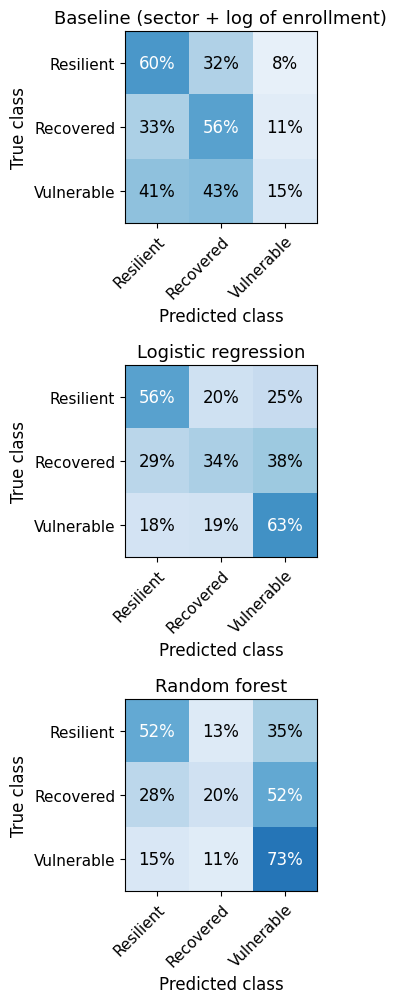

In [ ]:
# Visualization: confusion matrices (row percentages), all colleges
plot_confusion(main, 'm01_confusion_all_colleges')

In [ ]:
X, y = df[ALL_FEATURES], df['label_10']
folds = list(RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=1, random_state=SEED).split(X, y))
rows = []
for n in [50, 100, 200, 300, 500, 1000]:
    seed_means = []
    for seed in [0, 1, 2]:
        scores = []
        for train, test in folds:
            pipe = make_model('forest', ALL_FEATURES,
                              params={'model__n_estimators': n, 'model__min_samples_leaf': 50,
                                      'model__random_state': seed})
            pipe.fit(X.iloc[train], y.iloc[train])
            scores.append(f1_score(y.iloc[test], pipe.predict(X.iloc[test]), average='macro'))
        seed_means.append(np.mean(scores))
    rows.append({'trees': n, 'macro-F1 (mean of 3 seeds)': np.mean(seed_means),
                 'range across seeds': np.max(seed_means) - np.min(seed_means)})
tree_check = pd.DataFrame(rows).set_index('trees')
print(tree_check.round(4).to_string())
save_table(tree_check, 'tree check')

       macro-F1 (mean of 3 seeds)  range across seeds
trees                                                
50                          0.487               0.006
100                         0.483               0.013
200                         0.485               0.002
300                         0.483               0.007
500                         0.482               0.012
1000                        0.485               0.006


*   Both models did much better than the baseline. Macro-F1 was 0.494 for logistic regression and 0.483 for the random forest, while it was 0.346 for the baseline. MCC was 0.304 and 0.306, compared with 0.141. Balanced accuracy was 0.505 and 0.484, compared with 0.438.
*   The two models were close. Logistic regression scored a little higher on macro-F1 and balanced accuracy. These two metrics average the three classes, so each class counts the same. The random forest scored slightly higher on MCC. MCC counts every college once, so larger classes count more. The random forest found more vulnerable colleges, the largest class, and fewer recovered colleges, the smallest class. For macro-F1 and MCC, the gaps between the two models were smaller than the fold-to-fold SDs. Neither model was therefore clearly better.
*   The success criterion was met for both models on both metrics. The mean gains ranged from 0.137 to 0.165, and the fold-to-fold SDs ranged from 0.020 to 0.036. Both models beat the baseline in all 50 folds.
*   For both models, vulnerable colleges were the easiest to find. Recall for vulnerable was 0.625 for logistic regression and 0.733 for the random forest. Recovered colleges were the hardest. Precision was only 0.156 to 0.179 across the three models. Recall was 0.336 for logistic regression and 0.197 for the random forest.
*   Each model leaned in a different direction. The baseline leaned toward recovered. It labeled 43% of the vulnerable colleges as recovered and only 15% as vulnerable. The random forest leaned toward vulnerable. It labeled 35% of the resilient and 52% of the recovered colleges as vulnerable. Logistic regression was the most balanced. Its errors spread across all three classes.
*   Logistic regression chose C=0.01 in 37 of the 50 folds and C=0.001 in 12 folds. The baseline mostly chose a weak penalty (C=10 in 26 folds). The random forest chose a minimum leaf size of 50 in 20 folds and 20 in 18 folds. It chose 100, the largest leaf size on the grid, in only 4 folds. Most chosen values therefore fell inside the grids. Both models did best with simple settings: a strong penalty and large leaves.

## Step 4. Which groups of characteristics carry the signal?

**Sub-question 1**: Which groups of characteristics carry the signal, and is it stable?

**4.1 Shuffle one group**

The shuffling already happened in step 3. It builds one importance table for
each model, and checks whether the two models agree. It lines up each group's rank in the two models and computes the rank correlation. A value close to 1 means that both models ranked the groups in about the same order. A value close to 0 means no agreement, and a value below 0 means opposite orders.

In [ ]:
# Build one importance table for each model.
imp_lr = importance_table(main['logistic regression'])
imp_rf = importance_table(main['random forest'])
print('Logistic regression:')
print(imp_lr.to_string())
print()
print('Random forest:')
print(imp_rf.to_string())

# Check whether the two models agree
ranks = pd.DataFrame({'logistic regression': imp_lr['rank'], 'random forest': imp_rf['rank']})
print()
print('Rank correlation between the two models (Spearman):', round(ranks['logistic regression'].corr(ranks['random forest']), 2))
save_table(imp_lr, 'step4_importance_logistic')
save_table(imp_rf, 'step4_importance_forest')

Logistic regression:
                  importance (mean)  importance (SD)  top 3 (of 10 repeats)  rank
group                                                                            
student outcomes              0.030            0.010                      9     1
student body                  0.030            0.008                      8     2
pre-2018 trend                0.025            0.006                      7     3
size                          0.023            0.010                      4     4
finances                      0.017            0.008                      0     5
selectivity                   0.015            0.010                      2     6
price                         0.005            0.006                      0     7
location                      0.003            0.004                      0     8
sector                       -0.003            0.002                      0     9

Random forest:
                  importance (mean)  importance (SD)  top 3 (

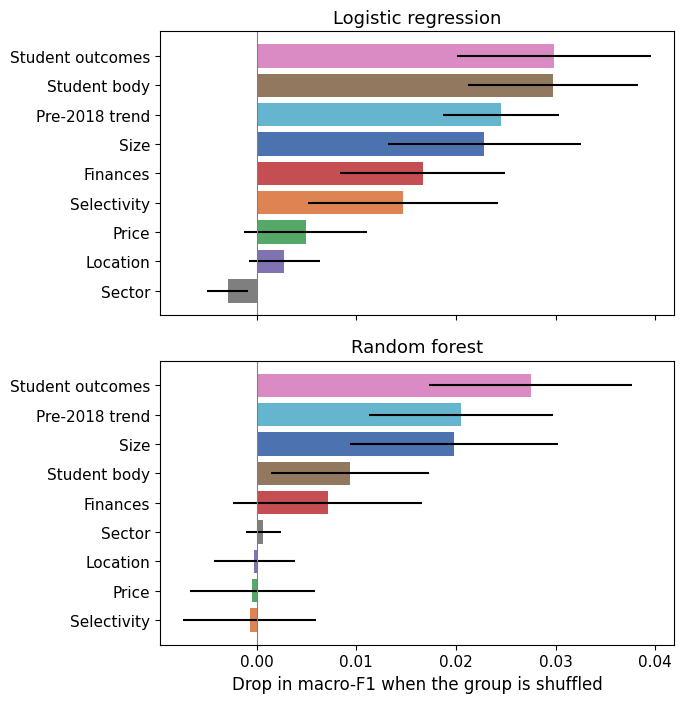

In [ ]:
# Visualization: grouped permutation importance, all colleges
plot_importance([imp_lr, imp_rf], ['logistic regression', 'random forest'], 'm02_importance_all_colleges')

The same four groups led in both models: student outcomes, the pre-2018 trend, size, and student body. Student outcomes ranked first in both models. Logistic regression spread its reliance over six groups: the top four, finances, and selectivity. Random forest relied mainly on three groups: student outcomes, pre-2018 trend, and size. Overall, the rank correlation was 0.78, so the two models mostly agreed on the order.

**4.2 Remove one group and refit**

In [ ]:
removed = {}
for name, kind in [('logistic regression', 'logistic'), ('random forest', 'forest')]:
    params = most_common_setting(main[name])
    print(name, '| fixed setting:', params if params else 'default')
    removed[name] = remove_group_check(df, 'label_10', ALL_FEATURES, GROUPS, kind, params)
removed_table = pd.concat(removed, axis=1)
print()
print('Drop in macro-F1 when the group is removed and the model is refit:')
print(removed_table.to_string())
save_table(removed_table, 'step4_remove_one_group')

logistic regression | fixed setting: {'model__C': 0.01}
random forest | fixed setting: {'model__min_samples_leaf': 50}

Drop in macro-F1 when the group is removed and the model is refit:
                     logistic regression                                 random forest                      
                 drop in macro-F1 (mean) drop in macro-F1 (SD) drop in macro-F1 (mean) drop in macro-F1 (SD)
group                                                                                                       
pre-2018 trend                     0.018                 0.018                   0.013                 0.024
student outcomes                   0.008                 0.012                   0.010                 0.020
student body                       0.005                 0.012                   0.008                 0.023
location                           0.003                 0.015                   0.006                 0.016
size                               0.003          

The largest mean drop was 0.019, for size in the random forest. In 4.1, the largest mean drop from shuffling was 0.030, for student outcomes and student body in logistic regression. After a refit, the other groups could take over much of the removed group’s signal. It shows the groups overlap. Much of each group's signal can also come from other group.

Pre-2018 trend had the largest drop in logistic regression (0.018) and the second largest in the random forest (0.013). In logistic regression, its drop was as large as its SD. It means the other groups could not fully replace its signal.

Size had the largest drop in the random forest (0.019) but a small drop in logistic regression (0.003). In the random forest, its drop was larger than its SD (0.015). Student outcomes ranked first in 4.1 (0.030 and 0.028), but its drops here were smaller (0.008 and 0.010).

**4.3 Odds ratio (logistic regression)**

Only logistic regression gives odds ratios. The random forest has no coefficients.

The table makes two comparisons: vulnerable vs. resilient and recovered vs. resilient. Resilient is the reference class. Each comparison has two columns:

*   The odds are the chance of being in the class divided by the chance of being resilient. It shows how these odds change for a 1 SD higher value, with the other characteristics held constant. Each OR is the median across the 50 logistic regressions fitted in step 3, one per fold.
*   Same direction is a stability check. It is the share of the 50 folds in which the OR fell on the same side of 1 as the median. A value of 1 means all 50 folds agreed. A value of 0.5 means half were above 1 and half were below, and the true direction is unknown.

In [ ]:
odds_ratios = odds_ratio_table(main['logistic regression'])
print('Odds ratio above 1: a higher value goes with higher odds of the class (vs. resilient)')
print(odds_ratios.to_string())
save_table(odds_ratios, 'step4_odds_ratios')

Odds ratio above 1: a higher value goes with higher odds of the class (vs. resilient)
                                                   group  OR, vulnerable vs. resilient  same direction, vulnerable vs. resilient  OR, recovered vs. resilient  same direction, recovered vs. resilient
characteristic                                                                                                                                                                                        
log of enrollment                                   size                         0.927                                     0.980                        0.723                                    1.000
more than one campus                                size                         1.037                                     0.980                        1.112                                    0.980
no first-time students                       selectivity                         1.110                                

*   Vulnerable vs. resilient. Five groups pointed in a clear direction. A higher pre-2018 trend (0.707), higher retention (0.815), and more endowment per student (0.872) went with lower odds of being vulnerable. A higher share with federal loans (1.395), a higher admission rate (1.373), and a higher default rate (1.138) went with higher odds. Net tuition revenue (0.908) and faculty salary (0.916) were also below 1. Vulnerable colleges were therefore already shrinking, less selective, more dependent on student borrowing, weaker on student outcomes, and less wealthy.
*   Recovered vs. resilient. Size stood out. Larger colleges had much lower odds of being recovered (0.723). A likely reason is that enrollment at small colleges changes more in percent terms. A few students make a large percent change at a small college. Normal ups and downs can therefore push it below the 10% line for a while before it comes back.



**4.4 SHAP values**

This step computes SHAP values for all 30 characteristics in both main models. SHAP values show how much each characteristic raised or lowered a college's predicted probability of being vulnerable, compared with the average prediction. Both models use the probability scale, so their values can be compared: random forest uses tree SHAP, and logistic regression uses permutation SHAP.

In [ ]:
from scipy import sparse

def to_original(names, features):
    # map each model column (e.g., 'cat__REGION_5' or 'num__ADM_RATE') back to its characteristic
    out = []
    for n in names:
        rem = n.split('__', 1)[1]
        out.append(rem if rem in features else next(c for c in features if rem.startswith(c + '_')))
    return out

def three_class_shap_oof(data, features, kind, target='vulnerable', n_background=100, perm_background=50):
    X = data[features]
    y = data['label_10']
    cv = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=1, random_state=SEED)   # same folds as repeat 1 of Step 3
    parts = []
    for train, test in cv.split(X, y):
        search = make_search(kind, features)
        search.fit(X.iloc[train], y.iloc[train])
        model = search.best_estimator_ if TUNE else search
        k = list(model.classes_).index(target)
        if kind == 'forest':
            # tree SHAP on the probability scale, then add the one-hot columns back into each characteristic
            prep, est = model.named_steps['prep'], model.named_steps['model']
            dense = lambda m: m.toarray() if sparse.issparse(m) else m
            background = dense(prep.transform(shap.sample(X.iloc[train], n_background, random_state=SEED)))
            e = shap.TreeExplainer(est, background, model_output='probability')(dense(prep.transform(X.iloc[test])))
            v = e.values[:, :, k] if e.values.ndim == 3 else e.values
            v = pd.DataFrame(v, columns=to_original(prep.get_feature_names_out(), features))
            v = v.T.groupby(level=0).sum().T
        else:
            # permutation SHAP on the probability scale, directly on the 30 characteristics
            dtypes = X.dtypes.to_dict()
            f = lambda arr: model.predict_proba(pd.DataFrame(arr, columns=features).astype(dtypes))[:, k]
            background = shap.sample(X.iloc[train], perm_background, random_state=SEED)   # real training colleges
            explainer = shap.PermutationExplainer(f, shap.maskers.Independent(background, max_samples=perm_background))
            v = pd.DataFrame(explainer(X.iloc[test], max_evals=4 * len(features) + 1, silent=True).values, columns=features)
        v.index = X.index[test]
        parts.append(v[features])
    return pd.concat(parts)

In [ ]:
shap_3 = {}
for name, kind in [('logistic regression', 'logistic'), ('random forest', 'forest')]:
    shap_3[name] = three_class_shap_oof(df, ALL_FEATURES, kind)
    print(name, 'done')
X_all = df.loc[shap_3['random forest'].index, ALL_FEATURES]

# Group SHAP: add up the SHAP values within each group, then compare the ranks with the shuffle ranks (4.1)
group_shap = {}
for name, imp in [('logistic regression', imp_lr), ('random forest', imp_rf)]:
    g = pd.DataFrame({grp: shap_3[name][cols].sum(axis=1) for grp, cols in GROUPS.items()})
    size = 100 * g.abs().mean()
    group_shap[(name, 'average effect size (points)')] = size.round(2) + 0.0
    group_shap[(name, 'SHAP rank')] = size.rank(ascending=False).astype(int)
    group_shap[(name, 'shuffle rank')] = imp['rank']
    rho = size.rank(ascending=False).corr(imp['rank'], method='spearman')
    print(f'{name}: rank correlation between SHAP and shuffle ranks = {rho:.2f}')
group_shap = pd.DataFrame(group_shap).sort_values(('random forest', 'SHAP rank'))
print()
print('Group SHAP, probability of being vulnerable (percentage points):')
print(group_shap.to_string())
save_table(group_shap, 'step4_shap_groups')

logistic regression done


 99%|===================| 955/963 [00:27<00:00]       

random forest done
logistic regression: rank correlation between SHAP and shuffle ranks = 0.73
random forest: rank correlation between SHAP and shuffle ranks = 0.77

Group SHAP, probability of being vulnerable (percentage points):
                          logistic regression                                       random forest                       
                 average effect size (points) SHAP rank shuffle rank average effect size (points) SHAP rank shuffle rank
pre-2018 trend                          3.470         2            3                        3.550         1            2
student outcomes                        2.570         5            1                        3.510         2            1
student body                            4.110         1            2                        3.160         3            4
finances                                3.200         3            5                        2.300         4            5
size                                    1.5

The rank correlation was 0.73 for logistic regression and 0.77 for random forest, meaning both model's SHAP ranks mostly agreed with their shuflle ranks. The pre-2018 trend ranked first or second in both models, while price, location, and sector ranked the bottom in both models, same as in the shuffle deck.

Three groups ranked differently: size ranked lower; finances ranked higher; and student outcomes ranked fifth in logistic regression, but second in random forest.

**Summary**: The signal came mainly from the pre-2018 trend, student outcomes, size, and student body. The same groups led in most view, but the exact order varied.

The pre-2018 trend was the most robust signal. It ranked near the top in all four views. Shuffling it lowered macro-F1 by 0.025 and 0.021. Removing it caused the largest drop in logistic regression (0.018). Its odds ratio for vulnerable was the furthest below 1 (0.707), and it ranked first or second by SHAP. The other groups could not replace its signal.

Student outcome was important. It ranked first when shuffled and its directions were clear. But removing it cost little, indicating other groups overlap with it. By SHAP, it ranked second in random forest but fifth in logistic regression.

Size was important for random forest. It ranked 4th in logistic regression and third in the random forest when shuffled. Removing it caused the largest drop in random forest. Its SHAP ranks were lower.

Sudent body and selectivity were more important for logistic regression. Federal loans and admision rate had the largest odds ratios above 1. After a refit, other groups could replace their signal.

Price, location, and sector almost have no signal once the other groups were known.

## Step 5. Public vs. private nonprofit

**Sub-question 2**: Do the signals differ between public and private nonprofit colleges?

The same tuned models run separately for each sector. Sector is left out because it does not vary inside a sector, so the baseline uses only the log of enrollment.

In [ ]:
# Run the models separately for each sector
sector_results = {}
for sec in ['public', 'private nonprofit']:
    data = df[df['sector'] == sec]
    res = {}
    res['baseline (size)'] = run_cv(data, 'label_10', ['log_enroll'], 'baseline')
    res['logistic regression'] = run_cv(data, 'label_10', SECTOR_FEATURES, 'logistic', groups=SECTOR_GROUPS)
    res['random forest'] = run_cv(data, 'label_10', SECTOR_FEATURES, 'forest', groups=SECTOR_GROUPS)
    sector_results[sec] = res
    print(sec, '| colleges:', len(data), '|', data['label_10'].value_counts().to_dict())
    print(score_table(res).to_string())
    print(gain_table(res, 'baseline (size)').to_string())
    print()

public | colleges: 526 | {'vulnerable': 256, 'resilient': 225, 'recovered': 45}
                     macro-F1  macro-F1 (SD)   MCC  MCC (SD)  balanced accuracy
model                                                                          
baseline (size)         0.383          0.029 0.183     0.051              0.447
logistic regression     0.514          0.042 0.365     0.071              0.529
random forest           0.509          0.049 0.393     0.078              0.513
                              mean gain  fold-to-fold SD folds with a gain  criterion met
model               metric                                                               
logistic regression macro-F1      0.131            0.042          50 of 50           True
                    MCC           0.182            0.071          50 of 50           True
random forest       macro-F1      0.126            0.049          50 of 50           True
                    MCC           0.209            0.078          50 o

In [ ]:
# mean per-class recall by sector
recall_rows = {}
for sec, res in sector_results.items():
    for name in ['logistic regression', 'random forest']:
        s = res[name]['scores']
        recall_rows[(sec, name)] = s[[c for c in s.columns if c.startswith('recall')]].mean()
recall_by_sector = pd.DataFrame(recall_rows).T
print('Mean per-class recall by sector:')
print(recall_by_sector.to_string())
save_table(recall_by_sector, 'step5_recall_by_sector')

Mean per-class recall by sector:
                                       recall resilient  recall recovered  recall vulnerable
public            logistic regression             0.589             0.322              0.674
                  random forest                   0.600             0.144              0.794
private nonprofit logistic regression             0.522             0.271              0.623
                  random forest                   0.473             0.204              0.728


In [ ]:
# Group importance by sector
imp_sector = {}
for sec, res in sector_results.items():
    for name in ['logistic regression', 'random forest']:
        imp_sector[(sec, name)] = importance_table(res[name])
compare = pd.DataFrame({key: t['importance (mean)'] for key, t in imp_sector.items()})
print('Mean drop in macro-F1 when the group is shuffled:')
print(compare.to_string())
save_table(compare, 'step5_importance_by_sector')

Mean drop in macro-F1 when the group is shuffled:
                              public                 private nonprofit              
                 logistic regression random forest logistic regression random forest
group                                                                               
finances                       0.032         0.014               0.002         0.009
location                       0.014         0.000               0.003        -0.001
pre-2018 trend                 0.015         0.010               0.019         0.016
price                         -0.000         0.003               0.011         0.004
selectivity                    0.022         0.001               0.016         0.001
size                           0.027         0.025               0.010         0.010
student body                   0.025         0.011               0.025         0.022
student outcomes               0.018         0.020               0.008         0.030


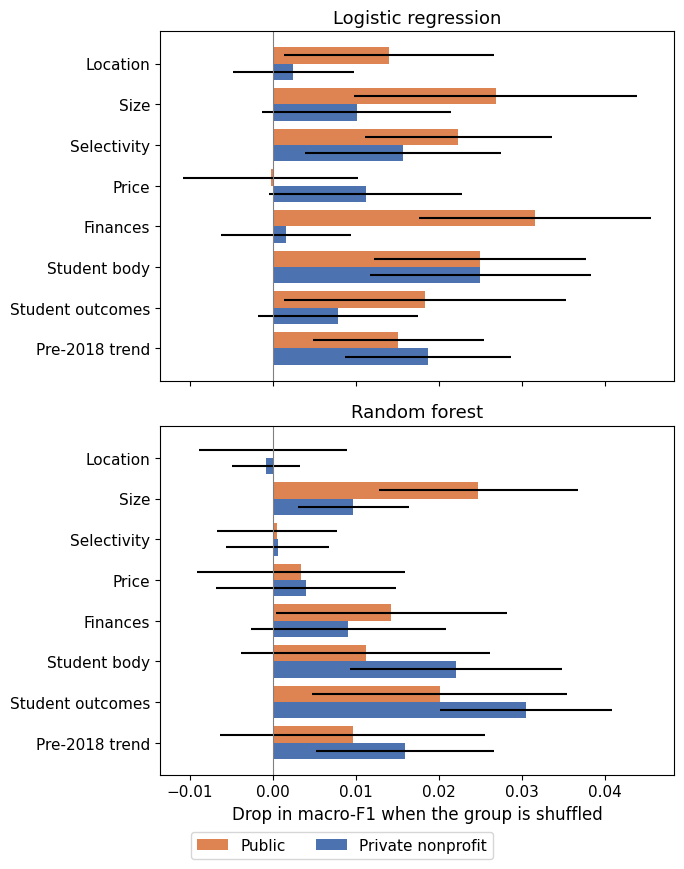

In [ ]:
# Visualiazation
group_names = list(SECTOR_GROUPS)
fig, axes = plt.subplots(2, 1, figsize=(7, 8.5), sharex=True)
for ax, name in zip(axes, ['logistic regression', 'random forest']):
    y = np.arange(len(group_names))
    for k, (sec, col) in enumerate([('public', '#DD8452'), ('private nonprofit', '#4C72B0')]):
        t = imp_sector[(sec, name)].reindex(group_names)
        ax.barh(y + (k - 0.5) * 0.4, t['importance (mean)'], height=0.4, xerr=t['importance (SD)'],
                color=col, label=sec.capitalize())
    ax.set_yticks(y)
    ax.set_yticklabels([GROUP_NAMES[g] for g in group_names])
    ax.invert_yaxis()
    ax.axvline(0, color='grey', linewidth=0.8)
    ax.set_title(nice_title(name))
axes[-1].set_xlabel('Drop in macro-F1 when the group is shuffled')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.03))
fig.tight_layout()
save_fig('m03_importance_by_sector')
plt.show()

In [ ]:
sector_table = pd.concat({(sec, name): imp_sector[(sec, name)]['importance (mean)']
                          for sec in ['public', 'private nonprofit']
                          for name in ['logistic regression', 'random forest']}, axis=1)
sector_table = tidy(sector_table.reindex(group_names))
print(sector_table.to_string())
save_table(sector_table, 'step5_importance_by_sector')

                              public                 private nonprofit              
                 logistic regression random forest logistic regression random forest
group                                                                               
location                       0.014         0.000               0.003        -0.001
size                           0.027         0.025               0.010         0.010
selectivity                    0.022         0.001               0.016         0.001
price                          0.000         0.003               0.011         0.004
finances                       0.032         0.014               0.002         0.009
student body                   0.025         0.011               0.025         0.022
student outcomes               0.018         0.020               0.008         0.030
pre-2018 trend                 0.015         0.010               0.019         0.016


**Summary**:

Both models beat the baseline in both sectors. The success criterion was met for both models on both metrics, and both models beat the baseline in all 50 folds. For public colleges, macro-F1 was 0.514 for logistic regression and 0.509 for random forest, compared to 0.383 for the baseline. For private ones, it was 0.467 for both models, compared with 0.316. The gains in macro-F1 were similar. Public colleges' MCC was higher. Their SD of macro-F1 were also larger, because the public sample was smaller. Recovered was the hardest calss in both sectors.

Sudent body and the pre-2018 trend carry the signal in both sectors. Size and finances matter more for public colleges. For private colleges, student outcomes was the top group in random forest. Selectivity matters only in logistic regression in both sectors.

## Step 6. Sensitivity check
Run the tuned models again with the 5% tolerance. If the scores and the top groups stay similar, the findings do not depend on the threshold.

In [ ]:
sens = {}
sens['baseline (sector + size)'] = run_cv(df, 'label_5', BASELINE_ALL, 'baseline')
sens['logistic regression'] = run_cv(df, 'label_5', ALL_FEATURES, 'logistic', groups=GROUPS)
sens['random forest'] = run_cv(df, 'label_5', ALL_FEATURES, 'forest', groups=GROUPS)

rows = []
for threshold, results in [('10%', main), ('5%', sens)]:
    for name, res in results.items():
        row = {'threshold': threshold, 'model': name,
               'macro-F1': res['scores']['macro_F1'].mean(), 'MCC': res['scores']['MCC'].mean()}
        if 'importance' in res:
            row['top three groups'] = ', '.join(importance_table(res).index[:3])
        else:
            row['top three groups'] = ''
        rows.append(row)
sensitivity = pd.DataFrame(rows)
print(sensitivity.to_string(index=False))
print()
print('Success criterion at 5%:')
print(gain_table(sens, 'baseline (sector + size)').to_string())
save_table(sensitivity.set_index(['threshold', 'model']), 'step6_sensitivity')

The scores barely changed with the 5% tolerance. Macro-F1 was 0.490 for logistic regression and 0.474 for the random forest, compared with 0.494 and 0.483 at 10%. The success criterion was still met for both models on both metrics, and both models beat the baseline in all 50 folds. At both thresholds, the top three groups came mainly from the same four: student outcomes, the pre-2018 trend, student body, and size. The order changed, however. At 5%, student outcomes dropped out of the top three for both models, and size moved up. Finances entered the top three for the random forest.

Conclusion: The main finding did not depend on the threshold. The models still beat the baseline. Mostly the same groups carried the signal, but their exact order was less stable.

## Step 7. Exit events
**Sub-question 3**: Do the private nonprofit colleges that closed or merged share a distinct 2018 profile?

Only 63 out of the 1,082 private nonprofit colleges exited. With so few exit events, the model uses only five characteristics, one from each group where exits differed most from the other colleges in the EDA (step 14). These characteristics are log of enrollment (size), retention rate (student outcome), share with federal loans (student body), average faculty salary (finances), and pre-2018 trend.

Two ways to handle the rare exit events are compared.
*   SMOTE: create synthetic exit colleges in the training folds
*   Class weights: no synthetic exit colleges

Both models are tuned with the same small grids. The baseline uses only the log of enrollment with SMOTE.

In [ ]:
# define the functions
EXIT_FEATURES = ['log_enroll', 'RET_FT4', 'PCTFLOAN', 'AVGFACSAL', 'trend_13_18']

def make_exit_model(kind, balance):
    # kind: 'logistic' or 'forest'; balance: 'SMOTE' or 'class weights'
    # SMOTE sits inside the pipeline, so it runs on the training fold only
    weights = 'balanced' if balance == 'class weights' else None
    steps = [('fill', SimpleImputer(strategy='median'))]
    if kind == 'logistic':
        steps.append(('scale', StandardScaler()))
    if balance == 'SMOTE':
        steps.append(('smote', SMOTE(random_state=SEED)))
    if kind == 'forest':
        steps.append(('model', RandomForestClassifier(n_estimators=N_TREES, min_samples_leaf=5, class_weight=weights,
                                                      random_state=SEED, n_jobs=-1)))
    else:
        steps.append(('model', LogisticRegression(max_iter=5000, class_weight=weights)))
    pipe = ImbPipeline(steps)
    if not TUNE:
        return pipe
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    return GridSearchCV(pipe, GRIDS[kind], cv=inner, scoring='average_precision')

def run_exit_cv(data, features, kind, balance, with_importance=False):
    X = data[features]
    y = data['exit_final'].astype(int)
    cv = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=SEED)
    rng = np.random.default_rng(SEED)
    rows = []
    imp_rows = []
    coef_rows = []
    for fold, (train, test) in enumerate(cv.split(X, y)):
        search = make_exit_model(kind, balance)
        search.fit(X.iloc[train], y.iloc[train])
        model = search.best_estimator_ if TUNE else search
        X_test = X.iloc[test]
        y_test = y.iloc[test]
        risk = model.predict_proba(X_test)[:, 1]          # predicted risk of exit
        pred = (risk >= 0.5).astype(int)
        auc = roc_auc_score(y_test, risk)
        rows.append({'repeat': fold // N_FOLDS,
                     'precision': precision_score(y_test, pred, zero_division=0),
                     'recall': recall_score(y_test, pred, zero_division=0),
                     'F1': f1_score(y_test, pred, zero_division=0),
                     'MCC': matthews_corrcoef(y_test, pred),
                     'ROC AUC': auc,
                     'PR AUC': average_precision_score(y_test, risk)})
        if kind == 'logistic':
            coef_rows.append(pd.Series(model.named_steps['model'].coef_[0], index=features))
        if with_importance:
            for col in features:
                shuffled = X_test.copy()
                shuffled[col] = X_test[col].values[rng.permutation(len(X_test))]
                drop = auc - roc_auc_score(y_test, model.predict_proba(shuffled)[:, 1])
                imp_rows.append({'repeat': fold // N_FOLDS, 'characteristic': col, 'importance': drop})
    result = {'scores': pd.DataFrame(rows)}
    if coef_rows:
        result['coefs'] = pd.DataFrame(coef_rows)
    if with_importance:
        result['importance'] = pd.DataFrame(imp_rows)
    return result

In [ ]:
# run the exit models
pnp = df[df['sector'] == 'private nonprofit']
print('Private nonprofit colleges:', len(pnp), '| exits:', int(pnp['exit_final'].sum()),
      '| share of exits:', round(pnp['exit_final'].mean(), 3))
print('Missing values among exits:', pnp.loc[pnp['exit_final'], EXIT_FEATURES].isna().sum().to_dict())

exit_results = {}
exit_results['baseline (size), SMOTE'] = run_exit_cv(pnp, ['log_enroll'], 'logistic', 'SMOTE')
exit_results['logistic regression, SMOTE'] = run_exit_cv(pnp, EXIT_FEATURES, 'logistic', 'SMOTE', with_importance=True)
exit_results['random forest, SMOTE'] = run_exit_cv(pnp, EXIT_FEATURES, 'forest', 'SMOTE', with_importance=True)
exit_results['logistic regression, class weights'] = run_exit_cv(pnp, EXIT_FEATURES, 'logistic', 'class weights')
exit_results['random forest, class weights'] = run_exit_cv(pnp, EXIT_FEATURES, 'forest', 'class weights')

rows = {}
for name, res in exit_results.items():
    rows[name] = res['scores'][['precision', 'recall', 'F1', 'MCC', 'ROC AUC', 'PR AUC']].mean()
exit_scores = pd.DataFrame(rows).T
print()
print('Exit model scores for the exit class (mean across folds):')
print(exit_scores.to_string())
save_table(exit_scores, 'step7_exit_scores')

Private nonprofit colleges: 1082 | exits: 63 | share of exits: 0.058
Missing values among exits: {'log_enroll': 0, 'RET_FT4': 5, 'PCTFLOAN': 0, 'AVGFACSAL': 1, 'trend_13_18': 1}

Exit model scores for the exit class (mean across folds):
                                    precision  recall    F1   MCC  ROC AUC  PR AUC
baseline (size), SMOTE                  0.136   0.688 0.227 0.214    0.761   0.182
logistic regression, SMOTE              0.156   0.760 0.258 0.262    0.822   0.289
random forest, SMOTE                    0.163   0.603 0.254 0.232    0.799   0.260
logistic regression, class weights      0.151   0.768 0.251 0.256    0.822   0.284
random forest, class weights            0.200   0.415 0.253 0.216    0.802   0.257


In [ ]:
# Flagged vs. overall
base_rate = pnp['exit_final'].mean()
lift = (exit_scores['precision'] / base_rate).round(2)
print('Overall exit rate:', round(base_rate, 3))
print('Exit rate among flagged colleges divided by the overall exit rate:')
print(lift.to_string())

Overall exit rate: 0.058
Exit rate among flagged colleges divided by the overall exit rate:
baseline (size), SMOTE               2.340
logistic regression, SMOTE           2.670
random forest, SMOTE                 2.810
logistic regression, class weights   2.590
random forest, class weights         3.440


In [ ]:
# Which characteristics carried the exit signal?
exit_imp = {}
for name in ['logistic regression, SMOTE', 'random forest, SMOTE']:
    per_repeat = exit_results[name]['importance'].groupby(['repeat', 'characteristic'])['importance'].mean().unstack()
    exit_imp[name] = per_repeat.mean()
exit_importance = pd.DataFrame(exit_imp).rename(index=nice_names).sort_values('random forest, SMOTE', ascending=False)
print(exit_importance.to_string())
save_table(exit_importance, 'step7_exit_importance')

                                      logistic regression, SMOTE  random forest, SMOTE
characteristic                                                                        
log of enrollment                                          0.076                 0.093
retention rate                                             0.029                 0.037
share with federal loans                                   0.050                 0.025
pre-2018 trend (log change)                                0.012                 0.016
average faculty salary ($ per month)                       0.002                -0.000


In [ ]:
# direction (odds ratios)
coefs = exit_results['logistic regression, SMOTE']['coefs']
exit_or = pd.DataFrame({'odds ratio (per 1 SD)': np.exp(coefs.median()),
                        'same direction (share of folds)': (np.sign(coefs) == np.sign(coefs.median())).mean()})
exit_or = exit_or.rename(index=nice_names)
print()
print('Odds ratio above 1: a higher value goes with higher odds of exit')
print(exit_or.to_string())
save_table(exit_or, 'step7_exit_odds_ratios')


Odds ratio above 1: a higher value goes with higher odds of exit
                                      odds ratio (per 1 SD)  same direction (share of folds)
log of enrollment                                     0.585                            1.000
retention rate                                        0.680                            1.000
share with federal loans                              1.805                            1.000
average faculty salary ($ per month)                  0.903                            0.880
pre-2018 trend (log change)                           0.835                            1.000


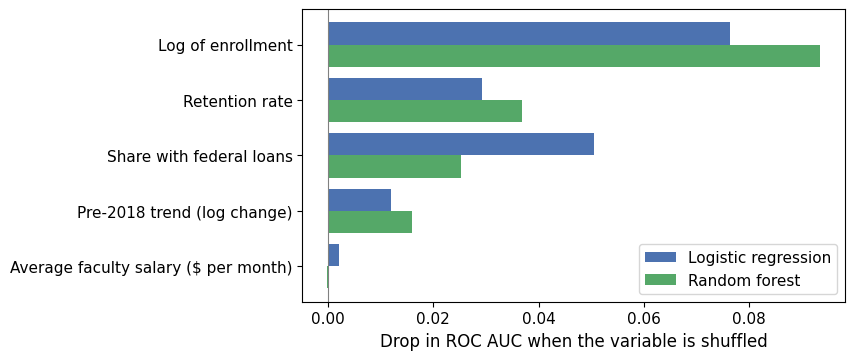

In [ ]:
# Visualization
fig, ax = plt.subplots(figsize=(7, 3.8))
y = np.arange(len(exit_importance))
ax.barh(y - 0.2, exit_importance['logistic regression, SMOTE'], height=0.4, color='#4C72B0', label='Logistic regression')
ax.barh(y + 0.2, exit_importance['random forest, SMOTE'], height=0.4, color='#55A868', label='Random forest')
ax.set_yticks(y)
ax.set_yticklabels([s[0].upper() + s[1:] for s in exit_importance.index])
ax.invert_yaxis()
ax.axvline(0, color='grey', linewidth=0.8)
ax.set_xlabel('Drop in ROC AUC when the variable is shuffled')
ax.legend()
save_fig('m04_exit_importance')
plt.show()

The models told exits apart from open colleges that they had not seen. ROC AUC was 0.822 for logistic regression and 0.799 for the random forest, both with SMOTE. With no difference in profile, it would be about 0.5. Both models also did better than the size-only baseline, which had a ROC AUC of 0.761. PR AUC was 0.289 for logistic regression and 0.260 for the random forest, compared with 0.182 for the baseline and 0.058 for random guessing. So, the exits had a different 2018 profile, and the diference went beyond size.

When each characteristic was shuffled, size caused the largest drop in ROC AUC. The share with federal loans and the retention rate came next. The pre-2018 trend mattered less, and faculty salary added almost nothing once the other four were known.

The odds ratios showed the direction of each characteristic. Larger size, higher retention, and a higher pre-2018 trend all went with lower odds of exit. A higher share of students with federal loans went with higher odds. These four directions held in every fold.

Logistic regression flagged 76% of the exits (recall 0.760), but most flagged colleges stayed open (precision 0.156). In other words, the profile was common among exits but not unique to them. SMOTE and class weights gave almost the same results, so the finding did not depend on how the rare exits were handled.

Summary: Exits shared a distinct 2018 profile. They were small, retained fewer students, had many students with federal loans, and were already shrinking. This profile signals risk, not a certain exit.

**SHAP**

SHAP values show how much a characteristic raised or lowered the predicted risk of exit, compared with the average prediction. A positive value means a higher predicted risk, and a negative value means a lower one. The models were trained with SMOTE, but the average prediction comes from a random sample of 100 real colleges in the training fold without SMOTE's synthetic exits. The two models' SHAP values are on different scales: logistic regression values are on the log-odds scale, and random forest values are on the probability scale. So only the ranks and directions can be compared between the models, not the sizes.

In [ ]:
def exit_shap_oof(data, features, kind, balance='SMOTE', n_background=100):
    # out-of-fold SHAP values for one repeat of the 5 folds
    X = data[features]
    y = data['exit_final'].astype(int)
    cv = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=1, random_state=SEED)   # same as repeat 1 of Step 7
    values, base, shown, rows = [], [], [], []
    for train, test in cv.split(X, y):
        search = make_exit_model(kind, balance)
        search.fit(X.iloc[train], y.iloc[train])
        model = search.best_estimator_ if TUNE else search
        # apply the model's own filling (and scaling for logistic regression), without SMOTE
        steps = [model.named_steps['fill']] + ([model.named_steps['scale']] if kind == 'logistic' else [])
        def transform(frame):
            out = frame
            for step in steps:
                out = step.transform(out)
            return out
        X_train_t, X_test_t = transform(X.iloc[train]), transform(X.iloc[test])
        background = shap.sample(X_train_t, n_background, random_state=SEED)      # real training colleges only
        est = model.named_steps['model']
        if kind == 'logistic':
            explainer = shap.LinearExplainer(est, background)                        # log-odds scale
        else:
            explainer = shap.TreeExplainer(est, background, model_output='probability')   # probability scale
        e = explainer(X_test_t)
        v = e.values[:, :, 1] if e.values.ndim == 3 else e.values                 # keep the exit class
        b = e.base_values[:, 1] if np.ndim(e.base_values) == 2 else e.base_values
        values.append(v)
        base.append(np.broadcast_to(b, (len(test),)))
        shown.append(model.named_steps['fill'].transform(X.iloc[test]))            # original units, for the colors
        rows.append(X.index[test])
    expl = shap.Explanation(values=np.vstack(values), base_values=np.concatenate(base), data=np.vstack(shown),
                            feature_names=[nice_names.get(f, f)[0].upper() + nice_names.get(f, f)[1:] for f in features])
    return expl, np.concatenate(rows)

In [ ]:
# summary table for both SMOTE models
shap_exit = {}
for name, kind in [('logistic regression, SMOTE', 'logistic'), ('random forest, SMOTE', 'forest')]:
    expl, rows = exit_shap_oof(pnp, EXIT_FEATURES, kind)
    is_exit = pnp.loc[rows, 'exit_final'].astype(bool).values
    shap_exit[name] = (expl, is_exit)
    table = pd.DataFrame({'mean |SHAP|, all colleges': np.abs(expl.values).mean(axis=0),
                          'mean SHAP, exits': expl.values[is_exit].mean(axis=0),
                          'mean SHAP, open colleges': expl.values[~is_exit].mean(axis=0),
                          'share of exits pushed toward exit': (expl.values[is_exit] > 0).mean(axis=0)},
                         index=expl.feature_names).sort_values('mean |SHAP|, all colleges', ascending=False)
    print(name, '- SHAP on the', 'log-odds' if kind == 'logistic' else 'probability', 'scale')
    print(tidy(table).to_string())
    print()
    save_table(tidy(table), f'step8_shap_{kind}')

logistic regression, SMOTE - SHAP on the log-odds scale
                                      mean |SHAP|, all colleges  mean SHAP, exits  mean SHAP, open colleges  share of exits pushed toward exit
Share with federal loans                                  0.260             0.196                    -0.005                              0.889
Log of enrollment                                         0.236             0.290                     0.000                              0.825
Retention rate                                            0.161             0.204                    -0.002                              0.778
Pre-2018 trend (log change)                               0.099             0.092                     0.002                              0.778
Average faculty salary ($ per month)                      0.064             0.045                    -0.001                              0.857



 97%|=================== | 423/434 [00:12<00:00]       

random forest, SMOTE - SHAP on the probability scale
                                      mean |SHAP|, all colleges  mean SHAP, exits  mean SHAP, open colleges  share of exits pushed toward exit
Log of enrollment                                         0.107             0.115                    -0.004                              0.730
Retention rate                                            0.088             0.071                    -0.005                              0.778
Share with federal loans                                  0.053             0.046                     0.002                              0.810
Pre-2018 trend (log change)                               0.041             0.042                     0.001                              0.698
Average faculty salary ($ per month)                      0.022             0.009                     0.000                              0.698



In [ ]:
for name, (expl, _) in shap_exit.items():
    shap_rank = pd.Series(np.abs(expl.values).mean(axis=0), index=expl.feature_names).rank(ascending=False)
    shuffle_rank = exit_importance[name].rank(ascending=False)
    shuffle_rank.index = [s[0].upper() + s[1:] for s in shuffle_rank.index]
    print(name)
    print(pd.DataFrame({'SHAP rank': shap_rank, 'shuffle rank': shuffle_rank.reindex(shap_rank.index)})
          .astype(int).sort_values('SHAP rank').to_string())
    print()

In the random forest, the SHAP ranking was the same as in the shuffle check: log of enrollment, retention rate, share with federal loans, pre-2018 trend, and average faculty salary. In logistic regression, the first two positions switched compared with the shuffle check: share with federal loans ranked first and log of enrollment second. All five characteristics pushed most exits toward exit: 77.8% to 88.9% of the exits in logistic regression and 69.8% to 81.0% in the random forest. However, average faculty salary pushed them by the smallest amount.

In [ ]:
for name, fname in [('logistic regression, SMOTE', 'm05_shap_exit_logistic'),
                    ('random forest, SMOTE', 'm06_shap_exit_forest')]:
    expl, is_exit = shap_exit[name]
    plt.figure()
    shap.plots.beeswarm(expl[is_exit], max_display=5, show=False, plot_size=(7, 3.5))
    scale = 'log-odds' if 'logistic' in name else 'probability'
    plt.gca().set_xlabel(f'SHAP value ({scale} of exit; right = pushed toward exit)')
    plt.title(nice_title(name.replace(', SMOTE', '')))
    save_fig(fname)
    plt.show()

In the beeswarm plots, the points on the right are exits pushed toward exit. They were mostly blue (low values) for size, retention, and the pre-2018 trend, and red (high values) for the share with federal loans. The colors compare each exit with the other exits.

Summary: SHAP confirmed the shuffle and odds ratio results above. The profile fit most exits, but not all of them.

## Step 8. Bias test with SHAP

This step uses the SHAP values from 4.4 to test whether the models labeled colleges as vulnerable partly because of whom they serve. It focuses on the student-body characteristics, plus completion and default rates, which partly reflect the same student populations. The other characteristics describe the college's own condition, such as size, finances, and the pre-2018 trend, so using them is not bias against a group of students.

In [ ]:
# Bias test: did the characteristics that describe whom a college serves push it toward "vulnerable"?
body = GROUPS['student body'] + ['C150_4', 'CDR3']   # student body, plus two outcome measures that can act as proxies
rows = []
for name, sv in shap_3.items():
    sv = sv.loc[X_all.index]
    rank = sv.abs().mean().rank(ascending=False)
    for c in body:
        x = X_all[c]
        if c == 'HBCU':
            high, low, groups = x == 1, x != 1, 'HBCU / not HBCU'       # HBCU is coded 1 = yes, 2 = no
        else:
            high, low, groups = x >= x.quantile(0.75), x <= x.quantile(0.25), 'top / bottom quarter'
        rows.append({'model': name, 'characteristic': nice_names.get(c, c),
                     'rank of 30': int(rank[c]),
                     'average effect size (points)': 100 * sv[c].abs().mean(),
                     'average effect, high group (points)': 100 * sv.loc[high, c].mean(),
                     'average effect, low group (points)': 100 * sv.loc[low, c].mean(),
                     'high / low group': groups})
bias_test = pd.DataFrame(rows).set_index(['model', 'characteristic'])
num_cols = [c for c in bias_test.columns if 'points' in c]
bias_test[num_cols] = bias_test[num_cols].round(2) + 0.0
print('Bias test, probability of being vulnerable (percentage points):')
print(bias_test.to_string())
save_table(bias_test, 'step8_shap_bias_test')

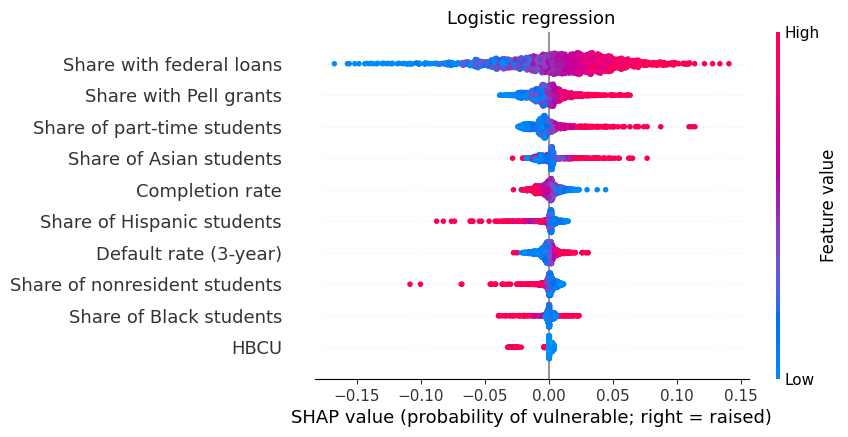

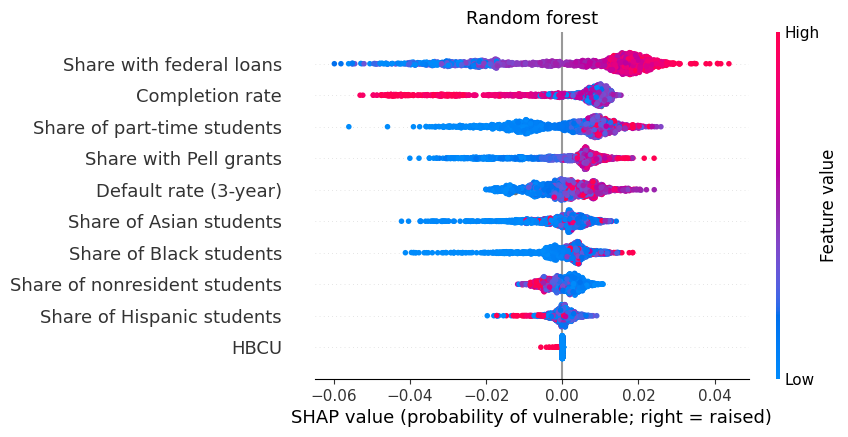

In [ ]:
# Visualization
for name, fname in [('logistic regression', 'm07_shap_vulnerable_logistic'),
                    ('random forest', 'm08_shap_vulnerable_forest')]:
    shown = X_all[body].copy()
    if 'HBCU' in shown:
        shown['HBCU'] = (shown['HBCU'] == 1).astype(int)          # 1 = HBCU, so red means HBCU
    names = [nice_names.get(c, c)[0].upper() + nice_names.get(c, c)[1:] for c in body]
    expl = shap.Explanation(values=shap_3[name].loc[X_all.index, body].values, data=shown.values, feature_names=names)
    plt.figure()
    shap.plots.beeswarm(expl, max_display=len(body), show=False, plot_size=(7, 4.5))
    plt.gca().set_xlabel('SHAP value (probability of vulnerable; right = raised)')
    plt.title(nice_title(name))
    save_fig(fname)
    plt.show()

The beeswarm plots show one point per college for each of the ten characteristics. A point on the right means the characteristic raised the college's predicted probability of being vulnerable, and a point on the left means it lowered it. Red means a high value and blue a low value; for HBCU, red means an HBCU. The characteristics are sorted by their average effect size.

Share with federal loans, share with Pell grants, and share of part-time students had the largest effects. Completion and default rates pointed the same way.A higher default rate raised the probability, and a higher completion rate lowered it. The racial and ethnic shares had smaller effects, with no common direction. A higher share of Hispanic students and a higher share of nonresident students lowered the probability in both models. The share of Asian students pointed the other way: a higher share raised the probability in logistic regression, and a very low share lowered it in random forest. The share of Black students had no clear direction in logistic regression. In random forest, a higher share raised the probability slightly, and a very low share lowered it. HBCU (Historically Black College or University) status lowered the probability in both models.